In [1]:
import pandas as pd 
import numpy as np 
import parquet

# maps
# import geopandas as gpd
# import json
# import branca.colormap as cm
# import folium
# from folium.plugins import TimestampedGeoJson

# visualization
# import plotly.graph_objects as go
import seaborn as sns 
import matplotlib.pyplot as plt 



In [17]:
DATA_DIR = Path('data')


trips = pd.read_parquet(DATA_DIR / 'trips', columns=['trip_id', 'start_station_id', 'year', 'start_time'])
trips['year'] = trips['year'].astype(int)  

stations = pd.read_parquet(DATA_DIR / 'stations')[['station_id', 'name', 'neighbourhood', 'ward']]

df = trips.merge(
    stations.rename(columns={
        'station_id': 'start_station_id', 'name': 'start_station_name',
        'neighbourhood': 'start_neighbourhood', 'ward': 'start_ward',
    }),
    on='start_station_id', how='left',
)



## Regressions: 

### Delta trips~ delta stations (panel + first differeciation)
### Poisson trips ~ workday + month + hour
### trip_duration ~ workday + month + hour


In [18]:
df.head()

,trip_id,start_station_id,year,start_time,start_station_name,start_neighbourhood,start_ward
0,53279,7100,2016,2016-07-09 01:03:00,Dundas St E / Regent Park Blvd,Regent Park,Toronto Centre
1,53394,7097,2016,2016-07-09 02:15:00,Riverdale Park North (Broadview Ave),North Riverdale,Toronto-Danforth
2,58314,7100,2016,2016-07-10 17:04:00,Dundas St E / Regent Park Blvd,Regent Park,Toronto Centre
3,60784,7033,2016,2016-07-11 01:45:00,Union Station,St Lawrence-East Bayfront-The Islands,Spadina-Fort York
4,93164,7059,2016,2016-07-18 13:35:00,Front St W / Blue Jays Way,Harbourfront-CityPlace,Spadina-Fort York


In [19]:
df_regr = df[~df.year.isin([2016, 2026])]

In [22]:
panel = (df_regr
            .groupby(['year', 'start_ward'], as_index=False)
            .agg(stations = ('start_station_id', 'nunique'),
                trips = ('trip_id', 'size'))
            .sort_values(['start_ward', 'year']) 
            
            .assign(stations_lag=lambda d: d.groupby('start_ward')['stations'].shift(1),
                    trips_lag=lambda d: d.groupby('start_ward')['trips'].shift(1))
            
            .assign(
                delta_stations=lambda d: d['stations'] - d['stations_lag'],
                delta_trips=lambda d: d['trips'] - d['trips_lag']
            )
            .dropna(subset=['delta_stations', 'delta_trips'])
 )

In [23]:
panel

,year,start_ward,stations,trips,stations_lag,trips_lag,delta_stations,delta_trips
10,2018,Beaches-East York,16,12207,7.0,4634,9.0,7573
22,2019,Beaches-East York,32,36627,16.0,12207,16.0,24420
35,2020,Beaches-East York,42,74382,32.0,36627,10.0,37755
54,2021,Beaches-East York,42,80855,42.0,74382,0.0,6473
73,2022,Beaches-East York,49,87465,42.0,80855,7.0,6610
...,...,...,...,...,...,...,...,...
72,2021,York South-Weston,4,4730,4.0,3416,0.0,1314
91,2022,York South-Weston,4,5175,4.0,4730,0.0,445
112,2023,York South-Weston,23,7325,4.0,5175,19.0,2150
135,2024,York South-Weston,27,15180,23.0,7325,4.0,7855


In [24]:
import statsmodels.api as sm

X = sm.add_constant(panel['delta_stations'])
y = panel['delta_trips']



In [25]:
model = sm.OLS(y, X).fit()

In [26]:
print(model.summary())

                            OLS Regression Results                            
Dep. Variable:            delta_trips   R-squared:                       0.070
Model:                            OLS   Adj. R-squared:                  0.063
Method:                 Least Squares   F-statistic:                     10.10
Date:                Sun, 15 Nov 2026   Prob (F-statistic):            0.00184
Time:                        19:10:09   Log-Likelihood:                -1748.4
No. Observations:                 136   AIC:                             3501.
Df Residuals:                     134   BIC:                             3507.
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                     coef    std err          t      P>|t|      [0.025      0.975]
----------------------------------------------------------------------------------
const            2.35e+04   1.08e+04      2.

In [27]:
model_cl = sm.OLS(y, X).fit(cov_type='cluster', cov_kwds={'groups': panel['start_ward']})
print(model_cl.summary())

                            OLS Regression Results                            
Dep. Variable:            delta_trips   R-squared:                       0.070
Model:                            OLS   Adj. R-squared:                  0.063
Method:                 Least Squares   F-statistic:                     1.798
Date:                Sun, 15 Nov 2026   Prob (F-statistic):              0.194
Time:                        19:10:14   Log-Likelihood:                -1748.4
No. Observations:                 136   AIC:                             3501.
Df Residuals:                     134   BIC:                             3507.
Df Model:                           1                                         
Covariance Type:              cluster                                         
                     coef    std err          z      P>|z|      [0.025      0.975]
----------------------------------------------------------------------------------
const            2.35e+04   1.45e+04      1.

## Calendar/weather demand model

### trips (hourly) ~ weather + workday + month + hour

### Get weather data

In [5]:
import holidays

OPEN_METEO_URL = "https://archive-api.open-meteo.com/v1/archive"

In [6]:
def fetch_weather(lat, lon, start_date, end_date, timezone="America/Toronto"):
    """Hourly historical weather for one point from Open-Meteo's free archive API
    (no key required). Returns a DataFrame indexed by hourly `date_hour`, columns
    temp_c/precip_mm/snowfall_cm/wind_kph."""
    resp = requests.get(
        OPEN_METEO_URL,
        params={
            "latitude": lat,
            "longitude": lon,
            "start_date": start_date,
            "end_date": end_date,
            "hourly": "temperature_2m,precipitation,snowfall,wind_speed_10m",
            "timezone": timezone,
        },
        timeout=60,
    )
    resp.raise_for_status()
    hourly = resp.json()["hourly"]
    return pd.DataFrame({
        "date_hour": pd.to_datetime(hourly["time"]),
        "temp_c": hourly["temperature_2m"],
        "precip_mm": hourly["precipitation"],
        "snowfall_cm": hourly["snowfall"],
        "wind_kph": hourly["wind_speed_10m"],
    })

In [7]:
def build_holiday_calendar(years):
    """Ontario statutory holidays for the given years as a {date: name} dict,
    for flagging is_holiday on the trips panel."""
    return dict(holidays.Canada(subdiv="ON", years=years))

In [ ]:
weather = fetch_weather(
        lat=43.6532, lon=-79.3832,
        start_date="2016-01-01", end_date=pd.Timestamp.today().strftime("%Y-%m-%d"),
    )

In [8]:
from pathlib import Path
# from utils import fetch_weather, build_holiday_calendar

In [9]:
WEATHER_PATH = Path("data/weather/city=toronto/part.parquet")

In [10]:
import requests

In [11]:
weather = fetch_weather(
        lat=43.6532, lon=-79.3832,
        start_date="2016-01-01", end_date=pd.Timestamp.today().strftime("%Y-%m-%d"),
    )

In [12]:
weather.head()

,date_hour,temp_c,precip_mm,snowfall_cm,wind_kph
0,2016-01-01 00:00:00,-0.0,0.0,0.0,18.9
1,2016-01-01 01:00:00,0.0,0.0,0.0,18.6
2,2016-01-01 02:00:00,0.0,0.0,0.0,20.0
3,2016-01-01 03:00:00,-0.0,0.0,0.0,20.8
4,2016-01-01 04:00:00,-0.1,0.0,0.0,21.3


In [13]:
WEATHER_PATH.parent.mkdir(parents=True, exist_ok=True)

In [14]:
weather.to_parquet(WEATHER_PATH)

In [16]:
weather.head()

,date_hour,temp_c,precip_mm,snowfall_cm,wind_kph
0,2016-01-01 00:00:00,-0.0,0.0,0.0,18.9
1,2016-01-01 01:00:00,0.0,0.0,0.0,18.6
2,2016-01-01 02:00:00,0.0,0.0,0.0,20.0
3,2016-01-01 03:00:00,-0.0,0.0,0.0,20.8
4,2016-01-01 04:00:00,-0.1,0.0,0.0,21.3


In [ ]:
# 2. Build the hourly system-wide panel from the existing trips df:
#    - date_hour = df['start_time'].dt.floor('h')
#    - trips = df.groupby('date_hour').size()
#    - monthly active_stations = df.groupby(df.start_time.dt.to_period('M'))['station_id'].nunique(), 
# broadcast onto each hourly row by year-month.



In [38]:
trips_h = df.copy()
trips_h['date_hour'] = trips_h['start_time'].dt.floor('h')
trips_h['year_month'] = trips_h['start_time'].dt.to_period('M')

In [40]:
hourly_trips = (trips_h
                .groupby('date_hour')
                .size()
                .reset_index(name='trips')
                )

In [41]:
hourly_trips.head()

,date_hour,trips
0,2016-07-01 00:00:00,125
1,2016-07-01 01:00:00,94
2,2016-07-01 02:00:00,94
3,2016-07-01 03:00:00,59
4,2016-07-01 04:00:00,56


In [48]:
monthly_active_stations = (trips_h
                            .groupby(df.start_time.dt.to_period('M'))['start_station_id']
                            .nunique()
                            .reset_index(name='active_stations')
                            .rename(columns = {'start_time':'year_month'})
                            )

In [49]:
monthly_active_stations.head()

,year_month,active_stations
0,2016-07,200
1,2016-08,200
2,2016-09,200
3,2016-10,200
4,2016-11,200


In [47]:
hourly_trips['year_month'] = hourly_trips['date_hour'].dt.to_period('M')        
hourly_trips.head()                                 

,date_hour,trips,year_month
0,2016-07-01 00:00:00,125,2016-07
1,2016-07-01 01:00:00,94,2016-07
2,2016-07-01 02:00:00,94,2016-07
3,2016-07-01 03:00:00,59,2016-07
4,2016-07-01 04:00:00,56,2016-07


In [50]:
hourly_trips = hourly_trips.merge(monthly_active_stations, on='year_month', how='left')

In [51]:
hourly_trips.head()

,date_hour,trips,year_month,active_stations
0,2016-07-01 00:00:00,125,2016-07,200
1,2016-07-01 01:00:00,94,2016-07,200
2,2016-07-01 02:00:00,94,2016-07,200
3,2016-07-01 03:00:00,59,2016-07,200
4,2016-07-01 04:00:00,56,2016-07,200


### calendar features

In [54]:
def build_holiday_calendar(years):
    """Ontario statutory holidays for the given years as a {date: name} dict,
    for flagging is_holiday on the trips panel."""
    return dict(holidays.Canada(subdiv="ON", years=years))

cal = build_holiday_calendar(range(2016, 2027))
cal

{datetime.date(2016, 1, 1): "New Year's Day",
 datetime.date(2016, 3, 25): 'Good Friday',
 datetime.date(2016, 7, 1): 'Canada Day',
 datetime.date(2016, 9, 5): 'Labour Day',
 datetime.date(2016, 12, 25): 'Christmas Day',
 datetime.date(2016, 12, 26): 'Boxing Day; Christmas Day (observed)',
 datetime.date(2016, 2, 15): 'Family Day',
 datetime.date(2016, 5, 23): 'Victoria Day',
 datetime.date(2016, 10, 10): 'Thanksgiving Day',
 datetime.date(2017, 1, 1): "New Year's Day",
 datetime.date(2017, 1, 2): "New Year's Day (observed)",
 datetime.date(2017, 4, 14): 'Good Friday',
 datetime.date(2017, 7, 1): 'Canada Day',
 datetime.date(2017, 9, 4): 'Labour Day',
 datetime.date(2017, 12, 25): 'Christmas Day',
 datetime.date(2017, 2, 20): 'Family Day',
 datetime.date(2017, 5, 22): 'Victoria Day',
 datetime.date(2017, 10, 9): 'Thanksgiving Day',
 datetime.date(2017, 12, 26): 'Boxing Day',
 datetime.date(2018, 1, 1): "New Year's Day",
 datetime.date(2018, 3, 30): 'Good Friday',
 datetime.date(2018, 7

In [56]:
hourly_trips['date'] = hourly_trips['date_hour'].dt.date
hourly_trips['is_holiday'] = hourly_trips['date'].isin(cal)
hourly_trips['dow'] = hourly_trips['date_hour'].dt.day_of_week
hourly_trips['month'] = hourly_trips['date_hour'].dt.month
hourly_trips['hour'] = hourly_trips['date_hour'].dt.hour
hourly_trips['is_weekend'] = hourly_trips['dow'].isin([5, 6])
hourly_trips['workday'] = ~hourly_trips['is_weekend'] & ~hourly_trips['is_holiday']

In [57]:
# merge weather
panel = hourly_trips.merge(weather, on='date_hour', how='left').dropna(subset=['temp_c', 'active_stations'])
panel.shape

(88794, 15)

In [65]:
panel.head()

,date_hour,trips,year_month,active_stations,date,is_holiday,dow,month,hour,is_weekend,workday,temp_c,precip_mm,snowfall_cm,wind_kph
0,2016-07-01 00:00:00,125,2016-07,200,2016-07-01,True,4,7,0,False,False,19.4,0.0,0.0,8.5
1,2016-07-01 01:00:00,94,2016-07,200,2016-07-01,True,4,7,1,False,False,18.8,0.0,0.0,10.1
2,2016-07-01 02:00:00,94,2016-07,200,2016-07-01,True,4,7,2,False,False,18.3,0.0,0.0,9.5
3,2016-07-01 03:00:00,59,2016-07,200,2016-07-01,True,4,7,3,False,False,17.9,0.0,0.0,7.4
4,2016-07-01 04:00:00,56,2016-07,200,2016-07-01,True,4,7,4,False,False,17.1,0.0,0.0,9.1


## Linear Regression

In [88]:
# panel['trips_per_station'] = panel['trips'] / panel['active_stations']

In [ ]:
# prepare design matrix:
X = pd.get_dummies(
        panel[['month', 'dow', 'hour']].astype('category'),
        drop_first=True, 
        )
X = pd.concat([X, panel[['workday', 'temp_c', 'precip_mm', 'snowfall_cm', 'wind_kph']]], axis=1)
X = sm.add_constant(X)
X.head()

,const,month_2,month_3,month_4,month_5,month_6,month_7,month_8,month_9,month_10,...,hour_19,hour_20,hour_21,hour_22,hour_23,workday,temp_c,precip_mm,snowfall_cm,wind_kph
0,1.0,False,False,False,False,False,True,False,False,False,...,False,False,False,False,False,False,19.4,0.0,0.0,8.5
1,1.0,False,False,False,False,False,True,False,False,False,...,False,False,False,False,False,False,18.8,0.0,0.0,10.1
2,1.0,False,False,False,False,False,True,False,False,False,...,False,False,False,False,False,False,18.3,0.0,0.0,9.5
3,1.0,False,False,False,False,False,True,False,False,False,...,False,False,False,False,False,False,17.9,0.0,0.0,7.4
4,1.0,False,False,False,False,False,True,False,False,False,...,False,False,False,False,False,False,17.1,0.0,0.0,9.1


In [77]:
# panel

In [78]:
y = panel['trips']

ols_model = sm.OLS(y, X).fit()
print(ols_model.summary())

                            OLS Regression Results                            
Dep. Variable:                  trips   R-squared:                       0.445
Model:                            OLS   Adj. R-squared:                  0.445
Method:                 Least Squares   F-statistic:                     1582.
Date:                Sun, 15 Nov 2026   Prob (F-statistic):               0.00
Time:                        22:18:19   Log-Likelihood:            -6.7740e+05
No. Observations:               88794   AIC:                         1.355e+06
Df Residuals:                   88748   BIC:                         1.355e+06
Df Model:                          45                                         
Covariance Type:            nonrobust                                         
                  coef    std err          t      P>|t|      [0.025      0.975]
-------------------------------------------------------------------------------
const         -12.2671     15.375     -0.798      

### Can we belive that results? 

In [83]:
fitted = ols_model.fittedvalues
resid = ols_model.resid 


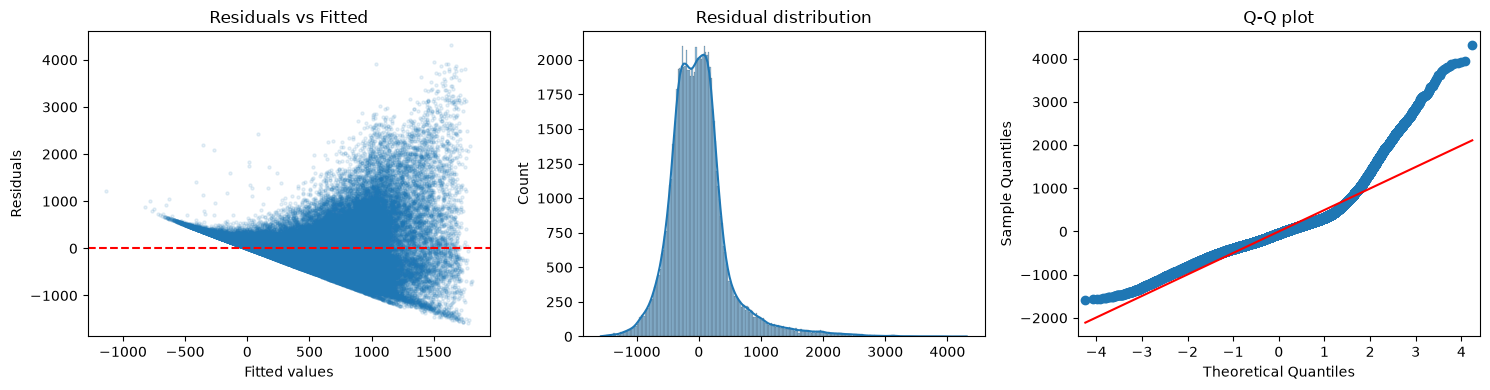

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

# 1. Residuals vs fitted 
axes[0].scatter(fitted, resid, alpha=0.1, s=5)
axes[0].axhline(0, color='red', linestyle='--')
axes[0].set_xlabel('Fitted values')
axes[0].set_ylabel('Residuals')
axes[0].set_title('Residuals vs Fitted')

# 2. Histogram 
sns.histplot(resid, kde=True, ax=axes[1])
axes[1].set_title('Residual distribution')

# 3. Q-Q plot 
from statsmodels.graphics.gofplots import qqplot
qqplot(resid, line='s', ax=axes[2])
axes[2].set_title('Q-Q plot')

plt.tight_layout()
plt.show()

- Residuals vs fitted plot shows a cone shape (variance increasing with fitted value). That's the heteroscedasticity
Moreover, some model's predictions below 0, when real counts can't go negative. 

- Residual Histogram and Q-Q plot shows that residuals are right-skew (long right tail), and there are heavy tails in the Q-Q plot deviating from the 45 degree line, especially at the top end.


In [ ]:
# We can try transform the respons
log_y = np.log(panel['trips'])

ols_model = sm.OLS(log_y, X).fit()
print(ols_model.summary())

                            OLS Regression Results                            
Dep. Variable:                  trips   R-squared:                       0.634
Model:                            OLS   Adj. R-squared:                  0.633
Method:                 Least Squares   F-statistic:                     3410.
Date:                Sun, 15 Nov 2026   Prob (F-statistic):               0.00
Time:                        23:11:20   Log-Likelihood:            -1.2447e+05
No. Observations:               88794   AIC:                         2.490e+05
Df Residuals:                   88748   BIC:                         2.495e+05
Df Model:                          45                                         
Covariance Type:            nonrobust                                         
                  coef    std err          t      P>|t|      [0.025      0.975]
-------------------------------------------------------------------------------
const           3.7501      0.030    123.482      

In [ ]:
log_fitted = ols_model.fittedvalues
log_resid = ols_model.resid 


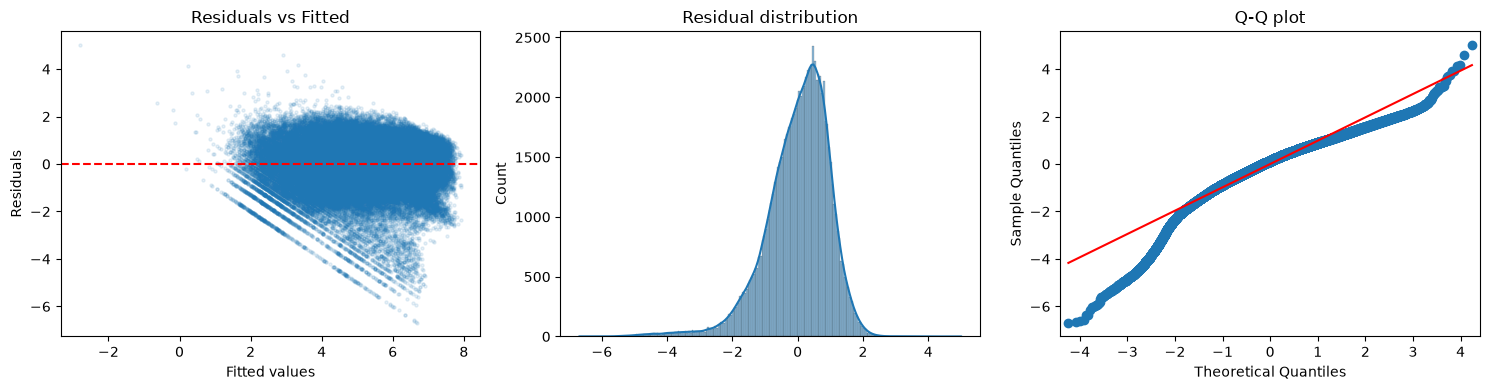

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

# 1. Residuals vs fitted 
axes[0].scatter(log_fitted, log_resid, alpha=0.1, s=5)
axes[0].axhline(0, color='red', linestyle='--')
axes[0].set_xlabel('Fitted values')
axes[0].set_ylabel('Residuals')
axes[0].set_title('Residuals vs Fitted')

# 2. Histogram 
sns.histplot(resid, kde=True, ax=axes[1])
axes[1].set_title('Residual distribution')

# 3. Q-Q plot 
from statsmodels.graphics.gofplots import qqplot
qqplot(resid, line='s', ax=axes[2])
axes[2].set_title('Q-Q plot')

plt.tight_layout()
plt.show()

It looks a little bit better, we avoided the possibility of negative predictions, and it overcomes much of the heteroscedacity in the 
untransformed data. However it's not a quite satisfactory solution, since predictions and inference are made in terms of the log of the response, rather than the responce. 
This leads to challenges in interpretation of the response.

### Poisson Regression for Counts. Where mean = variance

In [87]:
import statsmodels.api as sm
import statsmodels.formula.api as smf

In [93]:
panel.head()

,date_hour,trips,year_month,active_stations,date,is_holiday,dow,month,hour,is_weekend,workday,temp_c,precip_mm,snowfall_cm,wind_kph
0,2016-07-01 00:00:00,125,2016-07,200,2016-07-01,True,4,7,0,False,False,19.4,0.0,0.0,8.5
1,2016-07-01 01:00:00,94,2016-07,200,2016-07-01,True,4,7,1,False,False,18.8,0.0,0.0,10.1
2,2016-07-01 02:00:00,94,2016-07,200,2016-07-01,True,4,7,2,False,False,18.3,0.0,0.0,9.5
3,2016-07-01 03:00:00,59,2016-07,200,2016-07-01,True,4,7,3,False,False,17.9,0.0,0.0,7.4
4,2016-07-01 04:00:00,56,2016-07,200,2016-07-01,True,4,7,4,False,False,17.1,0.0,0.0,9.1


In [ ]:
poisson_model = smf.glm(
    'trips ~ C(month) + C(dow) + C(hour) + workday + temp_c + precip_mm + snowfall_cm + wind_kph',
    data=panel,
    family=sm.families.Poisson(),
    # offset=np.log(panel['active_stations']),
).fit()

In [61]:
print(poisson_model.summary())

                 Generalized Linear Model Regression Results                  
Dep. Variable:                  trips   No. Observations:                88794
Model:                            GLM   Df Residuals:                    88748
Model Family:                 Poisson   Df Model:                           45
Link Function:                    Log   Scale:                          1.0000
Method:                          IRLS   Log-Likelihood:            -4.7943e+06
Date:                Sun, 15 Nov 2026   Deviance:                   8.9568e+06
Time:                        19:51:50   Pearson chi2:                 9.24e+06
No. Iterations:                     7   Pseudo R-squ. (CS):              1.000
Covariance Type:            nonrobust                                         
                      coef    std err          z      P>|z|      [0.025      0.975]
-----------------------------------------------------------------------------------
Intercept          -2.1736      0.002  -11

In [62]:
print("Pearson chi2 / df_resid:", poisson_model.pearson_chi2 / poisson_model.df_resid)

Pearson chi2 / df_resid: 104.11469655055242


### Negative Binomial

In [95]:

nb_model = smf.glm(
    'trips ~ C(month) + C(dow) + C(hour) + workday + temp_c + precip_mm + snowfall_cm + wind_kph',
    data=panel,
    family=sm.families.NegativeBinomial(),
    offset=np.log(panel['active_stations']),
).fit()

print(nb_model.summary())
print("aic/Poisson:", poisson_model.aic, " negbinomial:", nb_model.aic)


/var/folders/xf/ygl5_zk57kn1rh2h1xj9fyx40000gn/T/ipykernel_97124/960514170.py:4: ValueWarning: Negative binomial dispersion parameter alpha not set. Using default value alpha=1.0.
  family=sm.families.NegativeBinomial(),


                 Generalized Linear Model Regression Results                  
Dep. Variable:                  trips   No. Observations:                88794
Model:                            GLM   Df Residuals:                    88748
Model Family:        NegativeBinomial   Df Model:                           45
Link Function:                    Log   Scale:                          1.0000
Method:                          IRLS   Log-Likelihood:            -5.7887e+05
Date:                Sun, 15 Nov 2026   Deviance:                       41669.
Time:                        23:34:18   Pearson chi2:                 4.29e+04
No. Iterations:                    63   Pseudo R-squ. (CS):             0.6573
Covariance Type:            nonrobust                                         
                      coef    std err          z      P>|z|      [0.025      0.975]
-----------------------------------------------------------------------------------
Intercept          -2.2889      0.031    -

In [ ]:
irr = np.exp(nb_model.params).rename('IRR')
irr.sort_values(ascending=False)